# SPX volatility surface: SVI vs SSVI and arbitrage

This notebook only **reads** saved results from `results/<snapshot>/`. To regenerate them: `python -m volsurf collect` then `python -m volsurf run`.

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
from volsurf.pipeline import BASELINE_SNAPSHOT, default_results_root, load_results
from volsurf import plotting as P

pd.set_option("display.float_format", "{:.4f}".format)
RESULT = default_results_root() / BASELINE_SNAPSHOT
res = load_results(RESULT)
res["summary"]

{'snapshot_id': '20261017T212629Z',
 'ticker': '^SPX',
 'source': 'Yahoo Finance via yfinance',
 'fetch_time_utc': '2026-10-17T21:26:29+00:00',
 'quote_time_utc': '2026-10-16T20:00:00+00:00',
 'quote_delay_note': 'Yahoo option quotes are delayed about 15 minutes; outside regular hours they are the last quotes of the prior session.',
 'spot': 7658.740234375,
 'n_expiries': 10,
 'expiries': ['2026-10-30',
  '2026-11-20',
  '2026-12-18',
  '2027-01-15',
  '2027-02-19',
  '2027-03-19',
  '2027-06-17',
  '2027-09-17',
  '2027-12-17',
  '2028-06-16'],
 'n_quotes': 2308,
 'clean_drop_counts': {'input_rows': 4791,
  'zero_bid': 266,
  'crossed_or_locked': 3,
  'wide_spread': 202,
  'deep_itm': 1079,
  'kept': 3241},
 'raw_mid_violations': 620,
 'raw_survive_bid_ask': 6,
 'raw_full_chain_mid_violations': 908,
 'raw_full_chain_survive_bid_ask': 126,
 'ssvi_constraints_ok': True,
 'ssvi_unconstrained_constraints_ok': False}

## Forwards and discount factors from put-call parity
One weighted regression of C − P on K per expiry; `n_used` is after the 3-MAD outlier pass.

In [2]:
res["forwards"][["expiry", "root", "T", "F", "D", "rate", "carry", "n_pairs", "n_used", "resid_std"]]

,expiry,root,T,F,D,rate,carry,n_pairs,n_used,resid_std
0,2026-10-30,SPXW,0.0384,7670.9456,0.9985,0.0381,0.0415,176,167,0.2360
1,2026-11-20,SPX,0.0953,7683.5910,0.9957,0.0448,0.0340,63,61,0.1295
2,2026-12-18,SPX,0.1720,7702.8463,0.9924,0.0446,0.0334,62,60,0.0971
3,2027-01-15,SPX,0.2487,7731.8135,0.9881,0.0480,0.0382,73,68,0.1890
4,2027-02-19,SPX,0.3446,7758.5514,0.9840,0.0467,0.0376,67,63,0.0915
5,2027-03-19,SPX,0.4212,7778.6070,0.9805,0.0468,0.0369,58,56,0.1201
6,2027-06-17,SPX,0.6678,7858.3483,0.9682,0.0484,0.0385,58,53,0.1300
7,2027-09-17,SPX,0.9198,7942.7976,0.9558,0.0492,0.0396,58,56,0.0660
8,2027-12-17,SPX,1.1692,8027.8718,0.9437,0.0495,0.0403,29,29,0.1719
9,2028-06-16,SPX,1.6678,8206.0021,0.9176,0.0516,0.0414,50,41,0.6485


## Raw quote arbitrage
OTM quote set (used for fitting). Mid violations vs violations that survive buying at the ask and selling at the bid.

In [3]:
res["raw_summary"]

,check,mid_violations,survive_bid_ask,max_profit_usd
0,butterfly,599,3,60.0000
1,slope_bound,21,3,500.0000
2,total,620,6,500.0000


In [4]:
v = res["raw_violations"]
v[v.survives_bid_ask]

,expiry,check,type,strikes,mid_violation,exec_profit,survives_bid_ask,profit_usd_per_contract,note,min_open_interest
375,2027-02-19,slope_bound,otm,4650/4675,2.7000,1.3000,True,130.0000,NaN,0.0000
559,2027-12-17,slope_bound,otm,4600/4650,3.4500,1.6000,True,160.0000,NaN,0.0000
564,2027-12-17,butterfly,otm,4550/4600/4650,2.5750,0.6000,True,60.0000,NaN,0.0000
565,2027-12-17,butterfly,otm,4650/4700/4750,2.6250,0.6000,True,60.0000,NaN,0.0000
579,2028-06-16,slope_bound,otm,6350/6375,13.4500,5.0000,True,500.0000,NaN,0.0000
613,2028-06-16,butterfly,otm,7125/7150/7175,10.0250,0.3000,True,30.0000,NaN,0.0000


Same checks on every clean quote including in-the-money strikes (diagnostic):

In [5]:
res["raw_summary_full_chain"]

,check,mid_violations,survive_bid_ask,max_profit_usd
0,butterfly,776,46,18335.0000
1,slope_bound,64,42,22699.8951
2,vertical,68,38,11510.0000
3,total,908,126,22699.8951


## Fit quality

In [6]:
res["fit_stats"].pivot(index="expiry", columns="model", values="rmse_volpts")

model,ssvi,ssvi_free,svi
expiry,,,
2026-10-30,4.7821,2.9784,0.1705
2026-11-20,3.2683,1.9822,0.1150
2026-12-18,2.9728,1.7203,0.2231
2027-01-15,2.8543,1.6741,0.1122
2027-02-19,2.4697,1.5788,0.1727
2027-03-19,2.6349,1.8279,0.1248
2027-06-17,2.3556,1.7717,0.1544
2027-09-17,1.9201,1.5423,0.1716
2027-12-17,1.8193,1.5368,0.2033


In [7]:
res["comparison"]

,model,rmse_volpts,mae_volpts,pct_inside_bid_ask,butterfly_slices_negative_g,butterfly_slices_negative_g_in_data,butterfly_slices_wing_over_lee,butterfly_slices_arbitrage,calendar_pairs_crossing,calendar_pairs_crossing_in_data,n_params
0,SVI,0.1638,0.1263,79.5927,5,0,0,5,6,0,50
1,SSVI,2.9963,1.9053,8.6222,0,0,0,0,0,0,13
2,SSVI (unconstrained),1.9263,1.4127,8.9255,0,0,0,0,0,0,13


## 1. Smiles with bid-ask vol bars and both fits

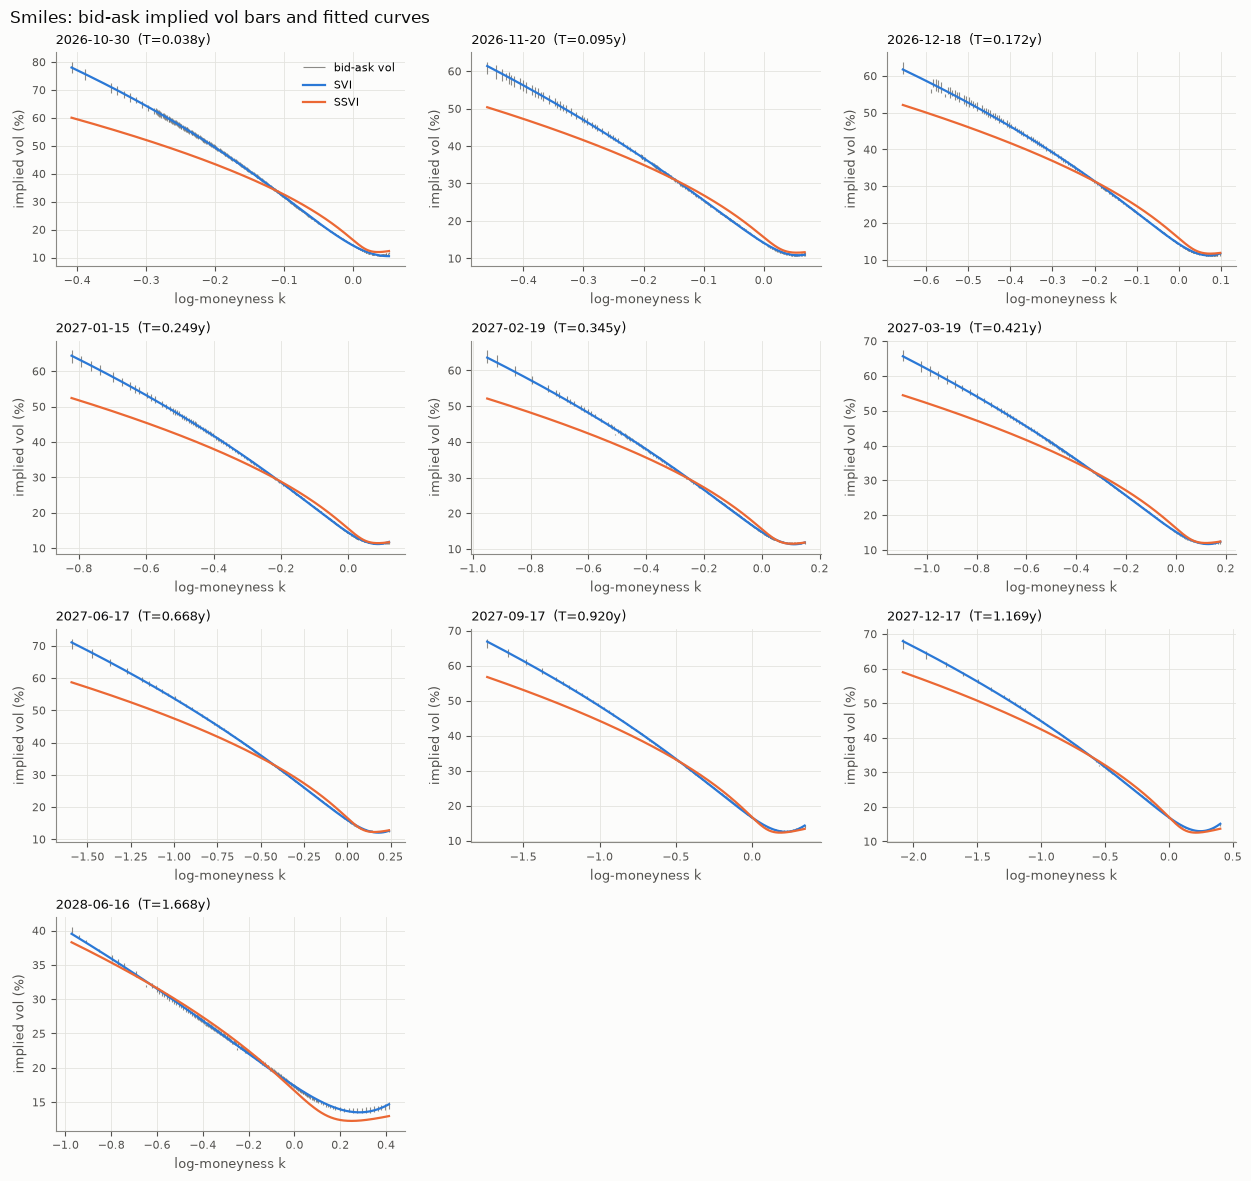

In [8]:
P.smiles_figure(res);

## 2. SSVI surface

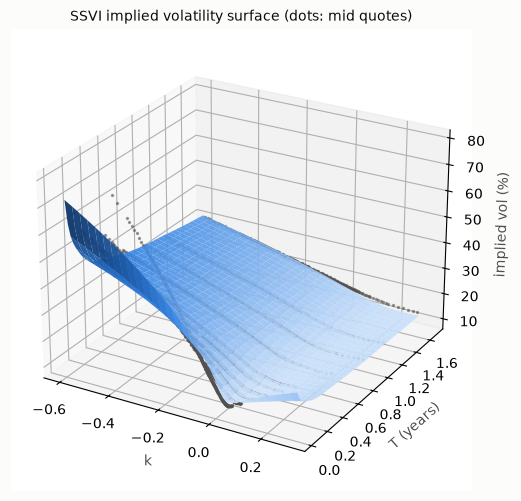

In [9]:
P.surface_figure(res, "ssvi");

## 3. g(k): where SVI goes negative

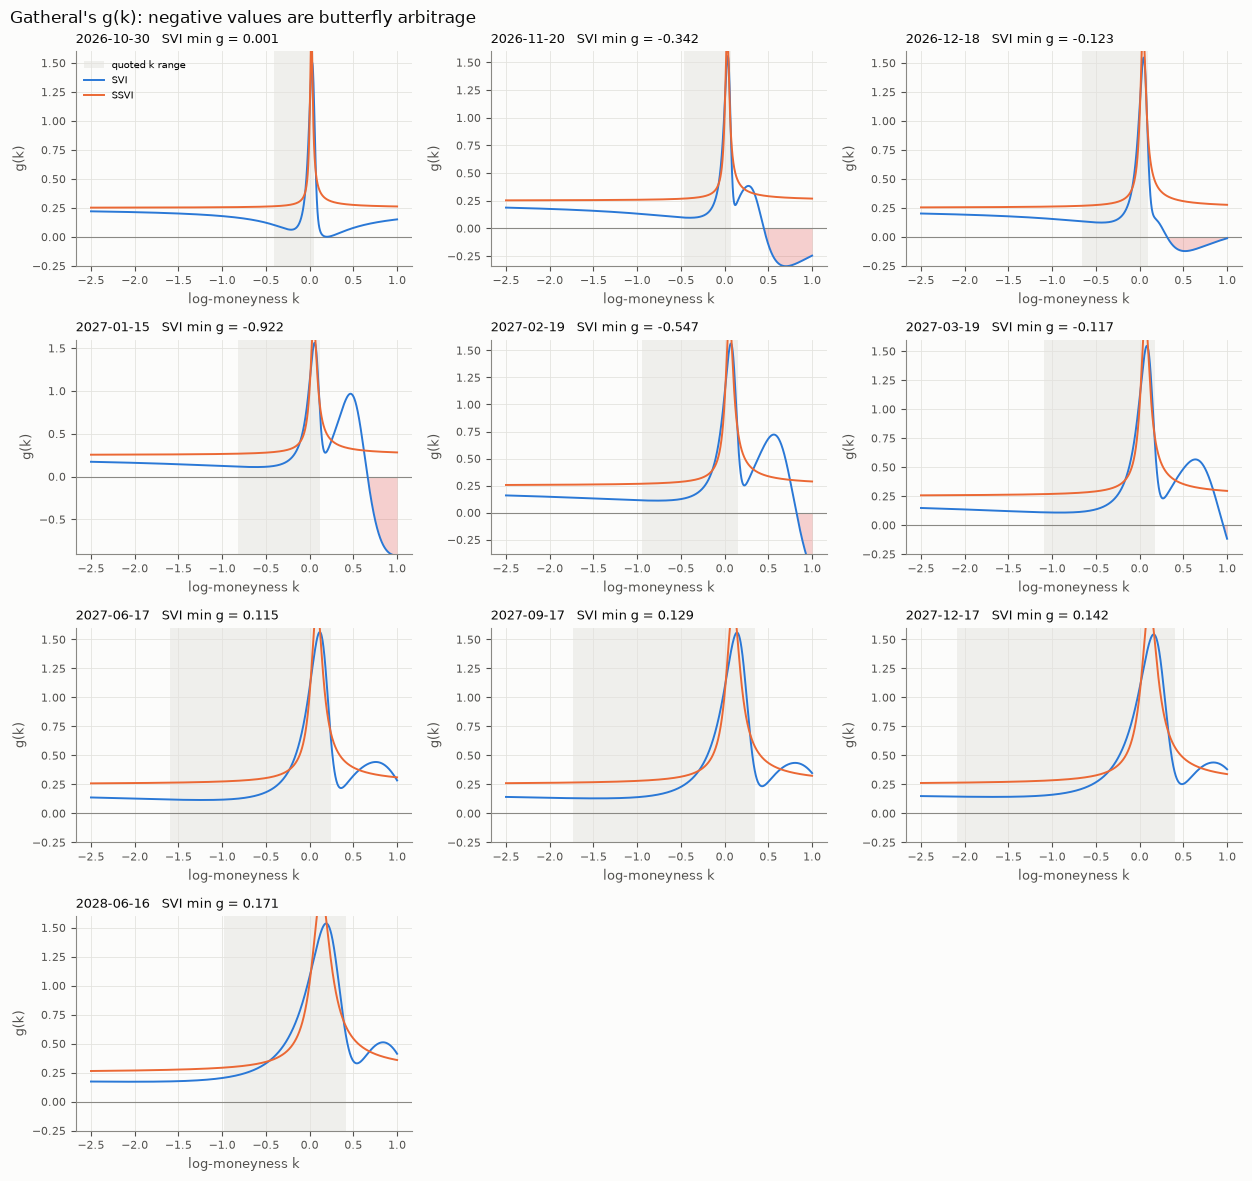

In [10]:
P.g_figure(res);

In [11]:
pd.DataFrame(res["fitted_arbitrage"]["svi"]["butterfly"]).T[["min_g", "k_at_min_g", "min_g_in_data_range", "negative_intervals"]]

,min_g,k_at_min_g,min_g_in_data_range,negative_intervals
2026-10-30,0.0010,0.1980,0.0618,[]
2026-11-20,-0.3422,0.7010,0.0958,"[[0.44799999999999995, 1.0]]"
2026-12-18,-0.1227,0.5190,0.1233,"[[0.31300000000000017, 1.0]]"
2027-01-15,-0.9223,0.9940,0.1109,"[[0.6630000000000003, 1.0]]"
2027-02-19,-0.5470,1.0000,0.1111,"[[0.8210000000000002, 1.0]]"
2027-03-19,-0.1174,1.0000,0.1081,"[[0.9550000000000001, 1.0]]"
2027-06-17,0.1154,-1.2310,0.1154,[]
2027-09-17,0.1293,-1.4720,0.1293,[]
2027-12-17,0.1421,-1.6800,0.1421,[]
2028-06-16,0.1715,-2.0250,0.2065,[]


## Calendar: SVI slices crossing

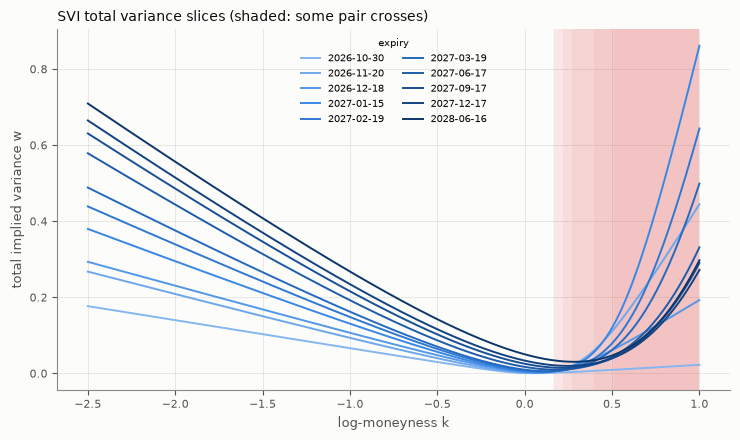

In [12]:
P.total_variance_figure(res, "svi");

In [13]:
pd.DataFrame(res["fitted_arbitrage"]["svi"]["calendar"]).T[["min_diff", "k_at_min_diff", "crossing_in_data_range", "crossing_intervals"]]

,min_diff,k_at_min_diff,crossing_in_data_range,crossing_intervals
2026-10-30->2026-11-20,0.0007,0.0610,False,[]
2026-11-20->2026-12-18,-0.2516,1.0000,False,"[[0.16199999999999992, 1.0]]"
2026-12-18->2027-01-15,0.0001,0.1940,False,[]
2027-01-15->2027-02-19,-0.2176,1.0000,False,"[[0.16999999999999993, 1.0]]"
2027-02-19->2027-03-19,-0.1449,1.0000,False,"[[0.21799999999999997, 1.0]]"
2027-03-19->2027-06-17,-0.1673,1.0000,False,"[[0.26800000000000024, 1.0]]"
2027-06-17->2027-09-17,-0.0413,1.0000,False,"[[0.399, 1.0]]"
2027-09-17->2027-12-17,-0.0181,1.0000,False,"[[0.5110000000000001, 1.0]]"
2027-12-17->2028-06-16,0.0071,0.5600,False,[]


## 4. Implied densities

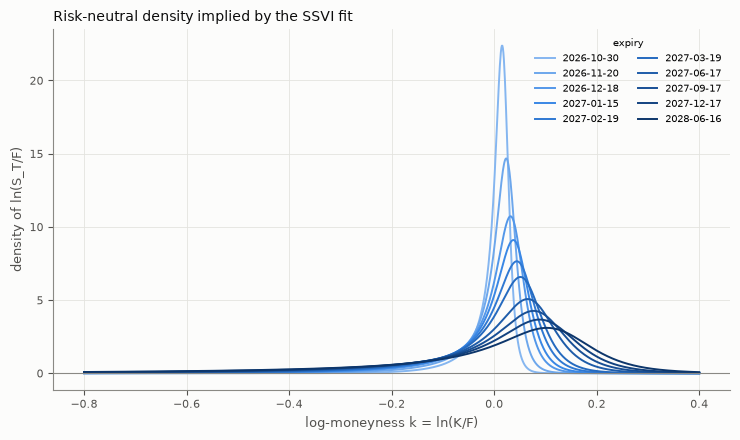

In [14]:
P.density_figure(res, "ssvi");

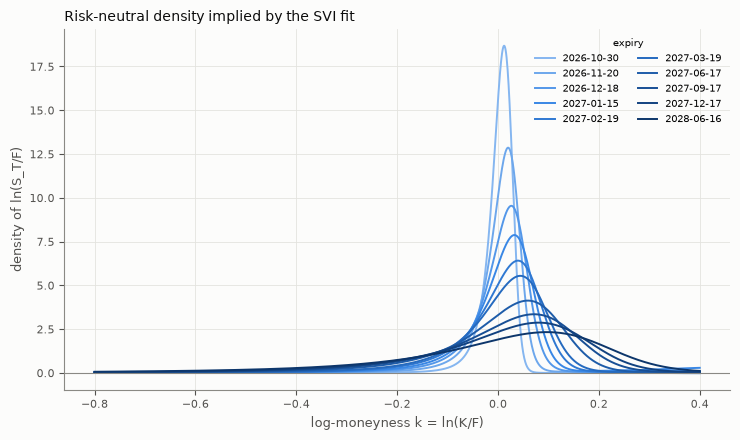

In [15]:
P.density_figure(res, "svi");

## SSVI constraints
Fitted parameters against the Gatheral and Jacquier (2014) conditions, constrained vs unconstrained.

In [16]:
pd.DataFrame({"SSVI": res["ssvi_meta"]["constraints"]} | {"rho/eta/gamma": {"rho": res["ssvi"].rho, "eta": res["ssvi"].eta, "gamma": res["ssvi"].gamma}})

,SSVI,rho/eta/gamma
rho_in_range,True,NaN
eta_positive,True,NaN
gamma_in_range,True,NaN
eta_rho_bound,True,NaN
theta_monotone,True,NaN
gj_thm42_part1,True,NaN
gj_thm42_part2,True,NaN
all_ok,True,NaN
rho,NaN,-0.6766
eta,NaN,1.1929


In [17]:
import json
json.loads((RESULT / "ssvi_unconstrained_params.json").read_text())["constraints"]

{'rho_in_range': True,
 'eta_positive': True,
 'gamma_in_range': False,
 'eta_rho_bound': True,
 'theta_monotone': True,
 'gj_thm42_part1': True,
 'gj_thm42_part2': False,
 'all_ok': False}